This is mostly a fun project for Mason to try and display the map as a gif showing when the fires burned.

In [6]:
# import packages
import platform
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import calendar
import matplotlib.pyplot as plt
import pygris

In [7]:
# import necessary packages
import platform
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import calendar
import matplotlib.pyplot as plt
import pygris
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Rectangle

import matplotlib.animation as animation


In [8]:

# import cleaned fire dataset

project_fldr = Path.cwd().parents[1]

raw_fldr = project_fldr / 'data' / 'raw'
processed_fldr = project_fldr / 'data' / 'processed'

# read in CSV
fire_shp_25 = gpd.read_file(processed_fldr / "fire_shp_25/fire_shp_25.shp")
fire_shp_25.info()

fire = fire_shp_25
fire = fire.to_crs("EPSG:26910")

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 521 entries, 0 to 520
Data columns (total 23 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   YEAR_       521 non-null    float64 
 1   STATE       521 non-null    str     
 2   AGENCY      521 non-null    str     
 3   UNIT_ID     521 non-null    str     
 4   FIRE_NAME   521 non-null    str     
 5   INC_NUM     521 non-null    str     
 6   IRWINID     469 non-null    str     
 7   ALARM_DATE  521 non-null    str     
 8   CONT_DATE   514 non-null    str     
 9   C_METHOD    521 non-null    int32   
 10  CAUSE       521 non-null    int32   
 11  OBJECTIVE   521 non-null    float64 
 12  GIS_ACRES   521 non-null    float64 
 13  COMPLEX_ID  17 non-null     str     
 14  COMPLEX_NA  17 non-null     str     
 15  COMMENTS    120 non-null    str     
 16  FIRE_NUM    0 non-null      object  
 17  Shape_Leng  521 non-null    float64 
 18  Shape_Area  521 non-null    float64 
 19  

Using the default year of 2024


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

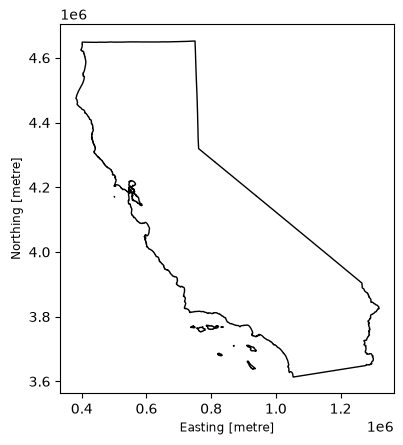

In [9]:
# get california map
# make map just for CA
state_outlines = pygris.states()
state_outlines.head()
ca_outline = state_outlines[state_outlines['NAME'] == 'California']


ca_outline = ca_outline.to_crs("EPSG:26910")

ca_outline.plot(color= "#ffffff", edgecolor = "#000000")



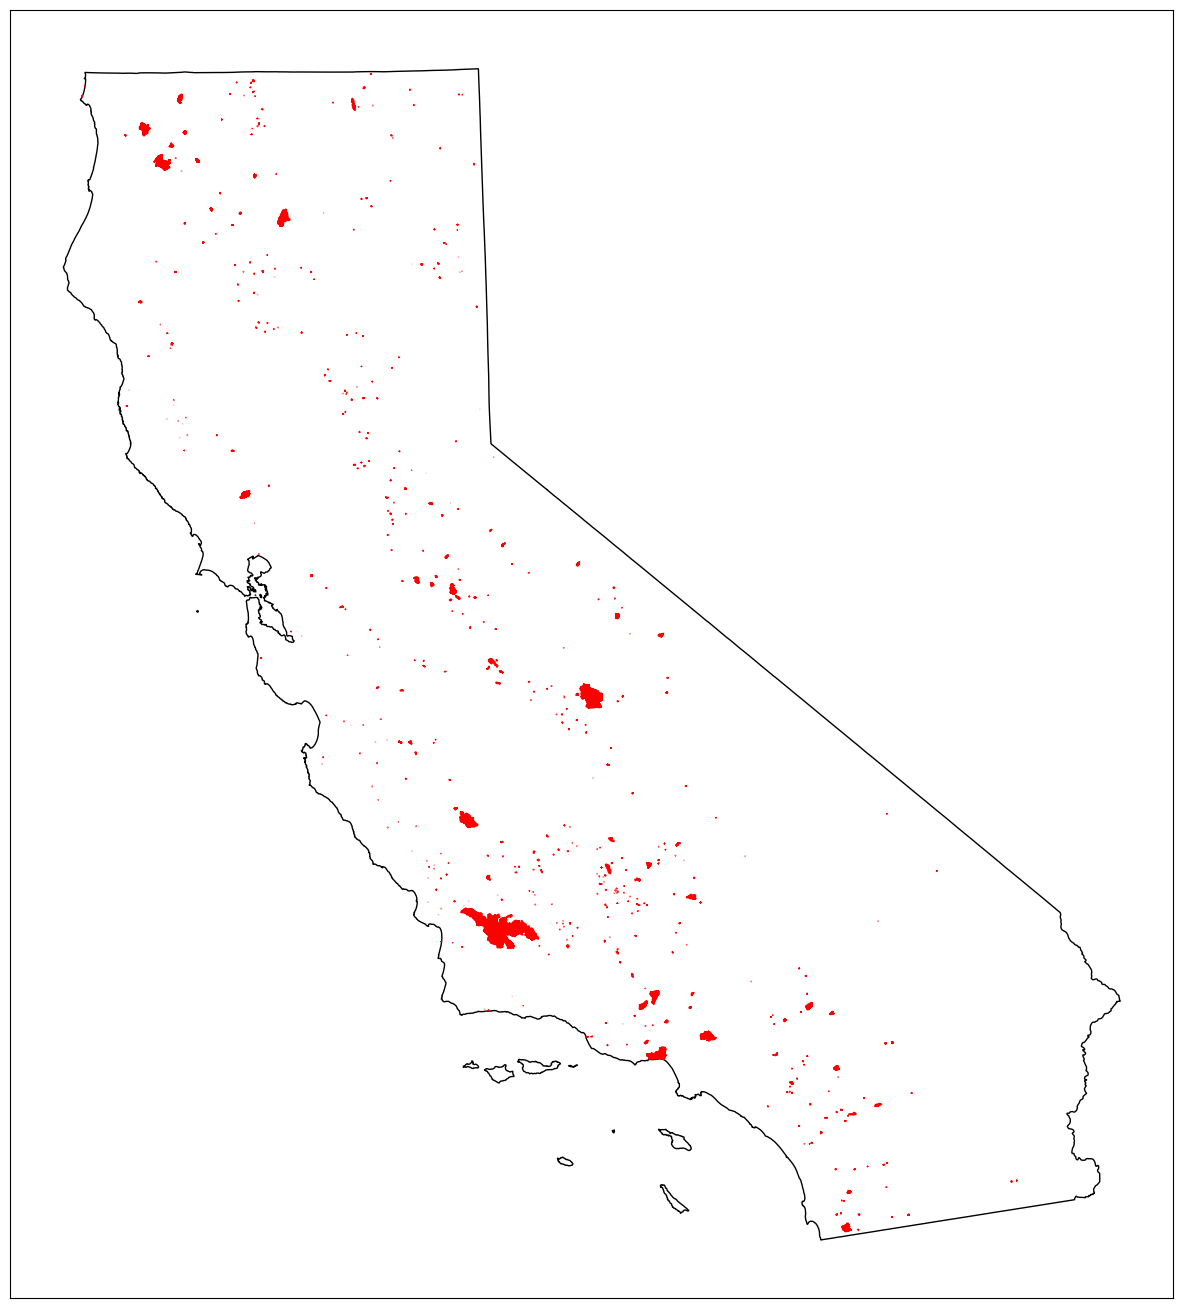

In [10]:
# make static map of the fires
fig, ax = plt.subplots(figsize=(15, 18))

ca_outline.plot(color= "#ffffff", edgecolor = "#000000", ax = ax)
fire.plot(ax=ax,figsize=(10,10), color='red', edgecolor='red')
# turn off the axes
ax.axis=('off')
ax.get_xaxis().set_visible(False) # Explicitly hide X elements
ax.get_yaxis().set_visible(False)


In [ ]:
# determine the appropriate columns
fire.head()

fire_timeline = fire.sort_values(["ALARM_DATE", "CONT_DATE"], ascending=True)

fire_timeline.head()

fire_timeline.value_counts(["ALARM_DATE"])

g = sns.

ALARM_DATE            
2025/09/02 00:00:00+00    23
2025/07/07 00:00:00+00    12
2025/08/25 00:00:00+00    12
2025/05/18 00:00:00+00    10
2025/07/05 00:00:00+00    10
                          ..
2025/12/01 00:00:00+00     1
2025/12/04 00:00:00+00     1
2025/12/06 00:00:00+00     1
2025/12/23 00:00:00+00     1
2025/12/24 00:00:00+00     1
Name: count, Length: 183, dtype: int64

In [20]:
# # Convert ALARM_DATE to datetime
fire_timeline["ALARM_DATE"] = pd.to_datetime(fire["ALARM_DATE"], errors="coerce")




In [21]:
# need to make set of images per date for which fires are active or not

# how can i make a dataframe that has a yes mark per fire per date